# Data Sparsity Analysis - Hybrid Movie Recommendation System

**Objective:** To study how data sparsity affects recommendation quality in the user-movie rating matrix, and to improve rating prediction when very few ratings are observed. This notebook (1) measures the sparsity of the HetRec MovieLens 2K matrix, (2) simulates sparser conditions by keeping only 100%, 75%, 50%, 25% and 10% of the training ratings.

The test set is never modified.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

## Step 1-2: Load the training and testing datasets

In [2]:
data_folder = Path("../dataset/processed")

train = pd.read_csv(data_folder / "train_ratings.csv")
test = pd.read_csv(data_folder / "test_ratings.csv")

print("Training and testing datasets loaded successfully!")

Training and testing datasets loaded successfully!


## Step 3: Overall dataset sparsity
Train and test are combined only to count all users and movies.

In [3]:
all_ratings = pd.concat([train, test], ignore_index=True)

total_users = all_ratings["userID"].nunique()
total_movies = all_ratings["movieID"].nunique()

total_possible = total_users * total_movies
total_ratings = len(all_ratings)

density = (total_ratings / total_possible) * 100
sparsity = 100 - density

print("DATASET INFORMATION")
print("-------------------")
print("Total Users:", total_users)
print("Total Movies:", total_movies)
print("Total Ratings:", total_ratings)
print("Training Ratings:", len(train))
print("Testing Ratings:", len(test))
print("Matrix Density:", round(density, 2), "%")
print("Matrix Sparsity:", round(sparsity, 2), "%")

DATASET INFORMATION
-------------------
Total Users: 2113
Total Movies: 9972
Total Ratings: 855439
Training Ratings: 683631
Testing Ratings: 171808
Matrix Density: 4.06 %
Matrix Sparsity: 95.94 %


## Step 4: Sparsity at different training-data levels

In [4]:
availability_levels = [100, 75, 50, 25, 10]

# Shuffle once so every experiment uses consistent, repeatable samples
shuffled_train = train.sample(frac=1, random_state=42).reset_index(drop=True)

results = []

for percentage in availability_levels:
    number_of_ratings = int(len(shuffled_train) * percentage / 100)
    selected_train = shuffled_train.iloc[:number_of_ratings]

    current_density = (len(selected_train) / total_possible) * 100
    current_sparsity = 100 - current_density

    results.append({
        "Data Availability (%)": percentage,
        "Training Ratings": len(selected_train),
        "Test Ratings": len(test),
        "Matrix Density (%)": round(current_density, 4),
        "Matrix Sparsity (%)": round(current_sparsity, 4),
    })

## Step 5: Results table

In [5]:
results_df = pd.DataFrame(results)

print("SPARSITY AT DIFFERENT DATA LEVELS")
print("---------------------------------")
print(results_df.to_string(index=False))
results_df

SPARSITY AT DIFFERENT DATA LEVELS
---------------------------------
 Data Availability (%)  Training Ratings  Test Ratings  Matrix Density (%)  Matrix Sparsity (%)
                   100            683631        171808              3.2444              96.7556
                    75            512723        171808              2.4333              97.5667
                    50            341815        171808              1.6222              98.3778
                    25            170907        171808              0.8111              99.1889
                    10             68363        171808              0.3244              99.6756


,Data Availability (%),Training Ratings,Test Ratings,Matrix Density (%),Matrix Sparsity (%)
0,100,683631,171808,3.2444,96.7556
1,75,512723,171808,2.4333,97.5667
2,50,341815,171808,1.6222,98.3778
3,25,170907,171808,0.8111,99.1889
4,10,68363,171808,0.3244,99.6756


## Step 6: Save the results

In [6]:
output_folder = Path("../outputs")
output_folder.mkdir(exist_ok=True)

results_df.to_csv(output_folder / "sparsity_results.csv", index=False)

## Step 7: Sparsity graph

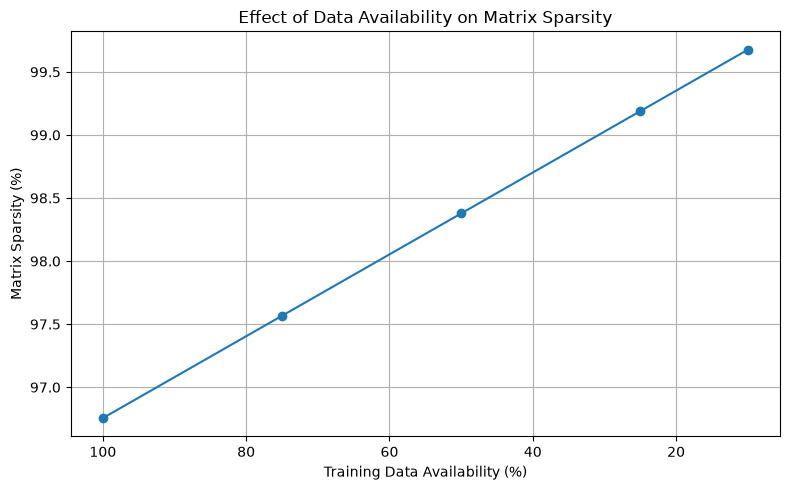

Results and graph saved successfully!


In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Data Availability (%)"],
    results_df["Matrix Sparsity (%)"],
    marker="o",
)

plt.xlabel("Training Data Availability (%)")
plt.ylabel("Matrix Sparsity (%)")
plt.title("Effect of Data Availability on Matrix Sparsity")

plt.gca().invert_xaxis()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_folder / "sparsity_vs_availability.png")
plt.show()

print("Results and graph saved successfully!")